In [1]:
import numpy
import scipy
from os.path import join
import matplotlib.pyplot as plt
import texplot
import matplotlib.ticker as mticker

# Imports from freealg
import freealg
from freealg import AlgebraicForm
from freealg.visualization import plot_flow, plot_mass, ridgeplot, plot_edges
from freealg.visualization._api_plot_util import _k_pow2_formatter

# Plotting options
plot_dir = './plots'
save_filename = 'stl'
latex = True

# STL10

Idx   Size   Repeat
---  -----   ------
0     1000        8
1     1414        5
2     2000        4
3     2828        2
4     4000        2
5     5656        1
6     8000        1
7    11313        1
8    16000        1

proc name: Intel(R) Xeon(R) Gold 6126 CPU @ 2.60GHz
num proc:  48
date:      2026-05-06 22:01:57 PDT



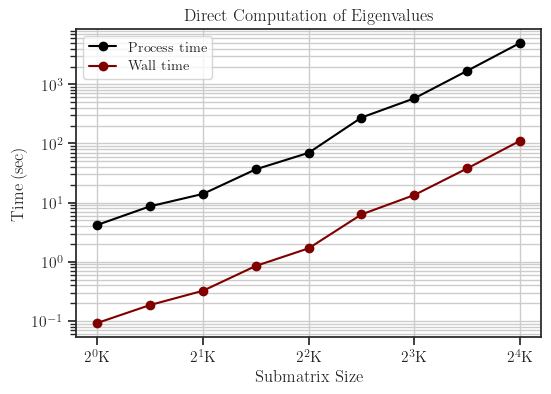

In [2]:
# Load input file
filename = 'stl10_n16K_eigs.npz'
dir_ = '/home/sia/work/scripts/free/Xperimental/hessian'
# dir_ = '/home/eecs/sameli/work/scripts/eig/'
data = numpy.load(join(dir_, filename), allow_pickle=True)
out = data['out'].item()

# Extract variables
sizes = out['sizes']                 # List of sizes of the submatrices
repeats = out['repeats']             # Repeats of sampling
eigs_repeated = out['eigs']          # List of eigenvalues per each submatrix
eigs = out['eigs']                   # List of eigenvalues per each submatrix
wall_times = out['wall_times']       # List of wall times taken to compute eigenvalues
proc_times = out['proc_times']       # List of CPU process times taken to compute eigenvalues
n, p = out['shape']                  # Dimension of the original matrix (largest matrix)
proc_name = out['proc_name']
num_proc = out['num_proc']
date = out['date']

# concatenate all repeats
max_repeat = 1
eigs = [None] * len(eigs_repeated)
for i in range(len(eigs_repeated)):
    rep_size = min(eigs_repeated[i].shape[0], max_repeat)
    eigs[i] = eigs_repeated[i][:rep_size, :].ravel()
    # s = eigs_repeated[i].shape[0]
    # shift = min(s-1, 2)
    # eigs[i] = eigs_repeated[i][shift:shift+rep_size, :].ravel()

# Sizes of submatrices
print('Idx   Size   Repeat')
print('---  -----   ------')
for i in range(sizes.size):
    print(f'{i:<2d}  {sizes[i]:>6d}  {repeats[i]:>7d}')
print('')
print(f'proc name: {proc_name}')
print(f'num proc:  {num_proc}')
print(f'date:      {date}')
print('')

# Plot wall and process times
with texplot.theme(use_latex=latex):
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(sizes, proc_times, '-o', color='black', label='Process time')
    ax.plot(sizes, wall_times, '-o', color='maroon', label='Wall time')
    ax.set_xlabel('Submatrix Size')
    ax.set_ylabel('Time (sec)')
    ax.set_title('Direct Computation of Eigenvalues')
    ax.legend(fontsize='small')
    ax.set_xscale('log', base=2)
    ax.xaxis.set_major_locator(mticker.LogLocator(base=2, subs=(1000/512.0,)))
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(_k_pow2_formatter))
    ax.set_yscale('log')
    ax.grid(True, which='both')
    plt.show()

In [3]:
# This dataset has eigenvalues very clsoe to zero, which sometiems they are slightly negative.
for i in range(len(eigs)):
    eigs[i] = numpy.abs(eigs[i])

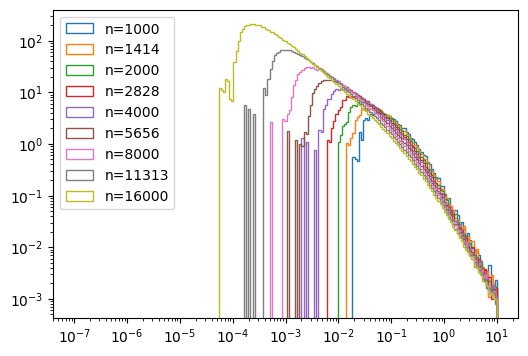

In [4]:
import numpy as np

plt.figure(figsize=(6, 4))

for i in range(len(eigs)):
    vals = eigs[i]
    vals = vals[vals > 1e-12]
    plt.hist(vals, bins=np.geomspace(1e-7, 1e1, 200),
             density=True, histtype="step", label=f"n={sizes[i]}")
plt.xscale("log")
plt.yscale("log")
plt.legend()
plt.show()

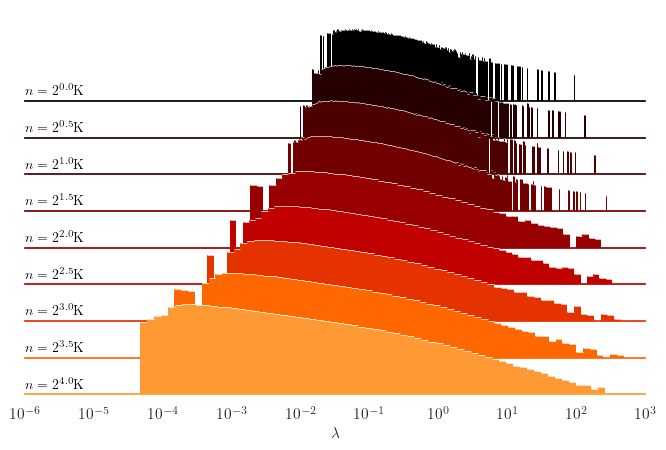

In [5]:
ridgeplot(sizes, eigs=eigs, log=True, scaley=False, hspace=-0.6,
          text_side='left',
          # xlim=(1e-7, 1e2),
          xlim=(1e-6, 1e3),
          ylim=(1e-6, 3e2),
          # ylim=(0, 1e-1),
          figsize=(8, 5),
          # label_mode='pow-int',
          label_mode='pow-dec',
          latex=latex, title='',
          save=False, nbins=200)

# Fit Spectral Curve

In [6]:
# # Index to choose the initial sub-matrix size
# # start_idx = 2  # TEST
# # start_idx = 4 # WORKED
# start_idx = 4

# # Detect support from histogram
# print('\n------------------------------------------')
# print('Support (detected from histogram):')
# support = freealg.supp(eigs[start_idx], method='hist', tol=0, nbins=150, log=True,
#                       print_info=True)

# # Stieltjes options (Homotopy)
# stieltjes_opt = dict(
#     n_levels = 200,
#     max_subdivide = 20,
#     anchor_mode = 'empirical',
#     anchor_y_min = 1e-5,  # 1e-5~1e-6 cause left bulks to fail
#     anchor_y_max = 10,
#     anchor_ratio = 1,  # 0.1~1 cause stieltjes_emp to not latch to poly roots
#     # anchor_match_tol = numpy.inf,  # disables anchor retry
#     # anchor_ratio_tol = numpy.inf,
#     anchor_match_tol = 0.1,       # retry if init anchor not mathc roots
#     anchor_ratio_tol = 0.9,
#     anchor_retry_factor = 3.0     # factor to multiple anchor height in retrial
# )

# # Inverse Stieltjes (Plemelj)
# inv_stieltjes_opt = dict(
#     delta = 1e-7,
#     delta_ladder_ratio = 2.0,
#     delta_ladder_size = 4,
#     # delta_ladder_size = 1,
#     delta_ladder_grid = 'linear',   # geometric, linear
#     z_query_delta = 'const',       # const, linear
#     method = 'chebfit',             # direct, polyfit, chebfit, poisson
#     # method = 'direct',             # direct, polyfit, chebfit, poisson
#     fit_degree = 2,
#     reg = 0.0,
#     fit_weight = 'small_delta',  # 'uniform, small_delta
# )

# # Estimate the initia ratio "c0" from "c" of the larger matrix
# data_size =  27648
# ratio = sizes[start_idx] / data_size

# # Smaller delta lowers the density baseline curve 1/x^2.
# af = AlgebraicForm(eigs[start_idx],
#                    ratio=ratio,
#                    # support=None,
#                    # support=[(9e-5, 5e0)],
#                    # support=[(2e-3, 3e2)], # WORKED
#                    support=[(3e-3, 8e1), (9e1, 3e2)],
#                    # support=[(1e-5, 1e-3), (2e-3, 1), (1, 5e2)],
#                    # support=[(1e-5, 1), (2, 1e3)],
#                    # support=support,
#                    n=sizes[start_idx],
#                    log=True,
#                    dtype='complex128',
#                    stieltjes_opt=stieltjes_opt,
#                    inv_stieltjes_opt=inv_stieltjes_opt)

# # We use deg_z = 1 since we guess the data is closely related to free Levy
# # model, where deg_z is always 1. We also set _deg_m = 5 to have the capacity
# # of representing 4 bulks once decompressed.
# print('\n------------------------------------------')

# # Combinations that work
# # deg_m, deg_z = 8, 5
# # deg_m, deg_z = 10, 5
# # deg_m, deg_z = 9, 5
# # deg_m, deg_z = 8, 4
# # deg_m, deg_z = 7, 3
# # deg_m, deg_z = 6, 6
# # deg_m, deg_z = 6, 3
# # deg_m, deg_z = 5, 5
# # deg_m, deg_z = 7, 5  # GOOD
# # deg_m, deg_z = 5, 3 # GOOD
# # deg_m, deg_z = 7, 5
# deg_m, deg_z = 5, 4  # GOOD
# # deg_m, deg_z = 5, 3

# deg_mu = 4
# mu = numpy.zeros((deg_mu+1, ), dtype=float)
# mu[0] = 1.0
# for i in range(1, mu.size):
#     if i == 1:
#         mu[i] = numpy.mean(af.eig)
#     else:
#         mu[i] = numpy.mean(af.eig**i)

# coeffs = af.fit(
#     deg_m, deg_z,
#     reg=0,
#     # r_min=1.8, r_max=2.2, n_r=5,
#     # r_min=1.5, r_max=2.2, n_r=5,
#     r_min=1.5, r_max=2.2, n_r=10,
#     # y_scale=0.1, gamma=0.05,
#     y_scale=0.1, gamma=0.08,
#     n_samples=4096 // 2,
#     cut_eps=0.01,
#     normalize=True,
#     # triangular=(None, None),
#     # triangular=(-2, 4),
#     # triangular=(-2, 3),   # VERY GOOD
#     # triangular=(-2, 3),   # VERY GOOD
#     triangular=(-1, 5),
#     # mu=mu,
#     mu=None,
#     mu_reg=None, verbose=True, plot=True)

# # print('\n------------------------------------------')
# # print('Support (estimated from polynomial):')
# # est_supp = af.support()
# # for i, supp in enumerate(est_supp):
# #     print(f'\tInterval {i+1}: ({supp[0]:>9.4f}, {supp[1]:>9.4f})')

# # print('\n------------------------------------------')
# # print('Atoms (estimated from polynomial):')
# # for i, atom in enumerate(af.atoms()):
# #     print(f'\tAtom {i+1}. x: {atom[0]:>4.1e}, '
# #           f'weight: {100.0*atom[1]:>4.1f}%')

# Fit Spectral Curve (Second Try)


------------------------------------------
Support (detected from histogram):
| bulk 1 | interval: (  0.01920,   0.02157) | center:   0.02035 |  mass:  0.20% |
| bulk 2 | interval: (  0.02285,   7.55051) | center:   0.41540 |  mass: 98.00% |
| bulk 3 | interval: (  8.00141,  10.09085) | center:   8.98560 |  mass:  0.40% |
| bulk 4 | interval: ( 11.33204,  12.72590) | center:  12.00876 |  mass:  0.20% |
| bulk 5 | interval: ( 13.48587,  15.14465) | center:  14.29121 |  mass:  0.30% |
| bulk 6 | interval: ( 16.04906,  17.00748) | center:  16.52132 |  mass:  0.10% |
| bulk 7 | interval: ( 19.09943,  20.24001) | center:  19.66145 |  mass:  0.10% |
| bulk 8 | interval: ( 27.04967,  28.66501) | center:  27.84563 |  mass:  0.10% |
| bulk 9 | interval: ( 30.37683,  32.19087) | center:  31.27070 |  mass:  0.10% |
| bulk 10 | interval: ( 38.30923,  43.02134) | center:  40.59698 |  mass:  0.20% |
| bulk 11 | interval: ( 45.59048,  48.31305) | center:  46.93203 |  mass:  0.10% |
| bulk 12 | inter

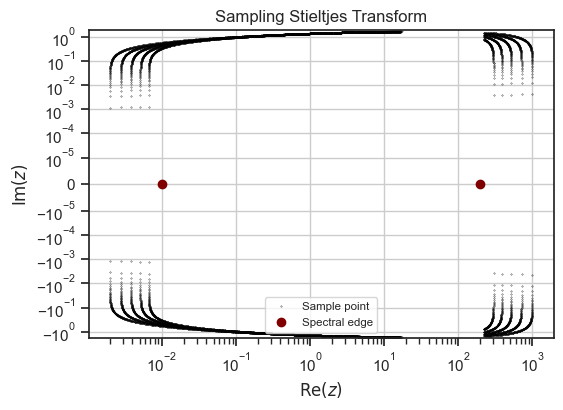

In [6]:
# Index to choose the initial sub-matrix size
# start_idx = 2  # TEST
# start_idx = 4 # WORKED
start_idx = 0

# Detect support from histogram
print('\n------------------------------------------')
print('Support (detected from histogram):')
support = freealg.supp(eigs[start_idx], method='hist', tol=0, nbins=150, log=True,
                      print_info=True)

# Stieltjes options (Homotopy)
stieltjes_opt = dict(
    n_levels = 200,
    max_subdivide = 20,
    anchor_mode = 'empirical',
    anchor_y_min = 1e-5,  # 1e-5~1e-6 cause left bulks to fail
    anchor_y_max = 10,
    anchor_ratio = 1,  # 0.1~1 cause stieltjes_emp to not latch to poly roots
    # anchor_match_tol = numpy.inf,  # disables anchor retry
    # anchor_ratio_tol = numpy.inf,
    anchor_match_tol = 0.1,       # retry if init anchor not mathc roots
    anchor_ratio_tol = 0.9,
    anchor_retry_factor = 3.0     # factor to multiple anchor height in retrial
)

# Inverse Stieltjes (Plemelj)
inv_stieltjes_opt = dict(
    delta = 1e-7,
    delta_ladder_ratio = 2.0,
    delta_ladder_size = 4,
    # delta_ladder_size = 1,
    delta_ladder_grid = 'linear',   # geometric, linear
    z_query_delta = 'const',       # const, linear
    method = 'chebfit',             # direct, polyfit, chebfit, poisson
    # method = 'direct',             # direct, polyfit, chebfit, poisson
    fit_degree = 2,
    reg = 0.0,
    fit_weight = 'small_delta',  # 'uniform, small_delta
)

# Estimate the initia ratio "c0" from "c" of the larger matrix
data_size =  27648
ratio = sizes[start_idx] / data_size

# Smaller delta lowers the density baseline curve 1/x^2.
af = AlgebraicForm(eigs[start_idx],
                   ratio=ratio,
                   # support=None,
                   # support=[(9e-5, 5e0)],
                   # support=[(2e-3, 3e2)], # WORKED
                   # support=[(3e-3, 8e1), (9e1, 3e2)],   ############
                   support=[(1e-2, 2e2)],
                   # support=[(1e-5, 1e-3), (2e-3, 1), (1, 5e2)],
                   # support=[(1e-5, 1), (2, 1e3)],
                   # support=support,
                   n=sizes[start_idx],
                   log=True,
                   dtype='complex128',
                   stieltjes_opt=stieltjes_opt,
                   inv_stieltjes_opt=inv_stieltjes_opt)

# We use deg_z = 1 since we guess the data is closely related to free Levy
# model, where deg_z is always 1. We also set _deg_m = 5 to have the capacity
# of representing 4 bulks once decompressed.
print('\n------------------------------------------')

# Combinations that work
# deg_m, deg_z = 8, 5
# deg_m, deg_z = 10, 5
# deg_m, deg_z = 9, 5
# deg_m, deg_z = 8, 4
# deg_m, deg_z = 7, 3
# deg_m, deg_z = 6, 6
# deg_m, deg_z = 6, 3
# deg_m, deg_z = 5, 5
# deg_m, deg_z = 7, 5  # GOOD
# deg_m, deg_z = 5, 3 # GOOD
# deg_m, deg_z = 7, 5
# deg_m, deg_z = 4, 3  # GOOD
deg_m, deg_z = 5, 5

deg_mu = 4
mu = numpy.zeros((deg_mu+1, ), dtype=float)
mu[0] = 1.0
for i in range(1, mu.size):
    if i == 1:
        mu[i] = numpy.mean(af.eig)
    else:
        mu[i] = numpy.mean(af.eig**i)

coeffs = af.fit(
    deg_m, deg_z,
    reg=0,
    # r_min=1.8, r_max=2.2, n_r=5,
    # r_min=1.5, r_max=2.2, n_r=5,
    r_min=1.5, r_max=2.2, n_r=5,
    # y_scale=0.1, gamma=0.05,
    y_scale=0.1, gamma=0.1,
    n_samples=4096 // 2,
    cut_eps=0.01,
    normalize=True,
    # triangular=(None, None),
    # triangular=(-2, 4),
    # triangular=(-2, 3),   # VERY GOOD
    # triangular=(-2, 3),   # VERY GOOD
    triangular=(-1, 3),
    # mu=mu,
    mu=None,
    mu_reg=None, verbose=True, plot=True)

# print('\n------------------------------------------')
# print('Support (estimated from polynomial):')
# est_supp = af.support()
# for i, supp in enumerate(est_supp):
#     print(f'\tInterval {i+1}: ({supp[0]:>9.4f}, {supp[1]:>9.4f})')

# print('\n------------------------------------------')
# print('Atoms (estimated from polynomial):')
# for i, atom in enumerate(af.atoms()):
#     print(f'\tAtom {i+1}. x: {atom[0]:>4.1e}, '
#           f'weight: {100.0*atom[1]:>4.1f}%')

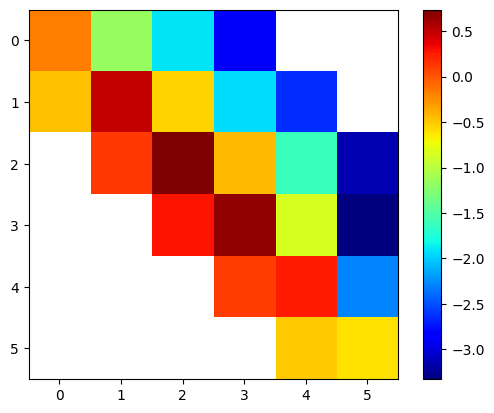

In [7]:
%matplotlib inline

p = plt.imshow(numpy.log10(numpy.abs(af.coeffs.real)), cmap=plt.cm.jet)
plt.colorbar(p)
plt.show()

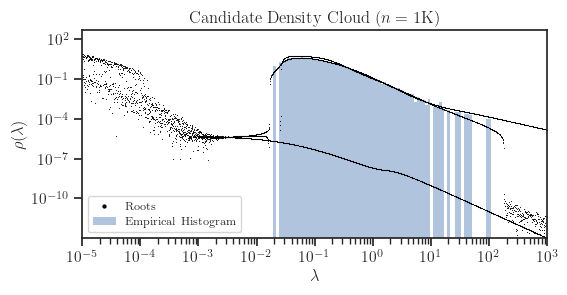

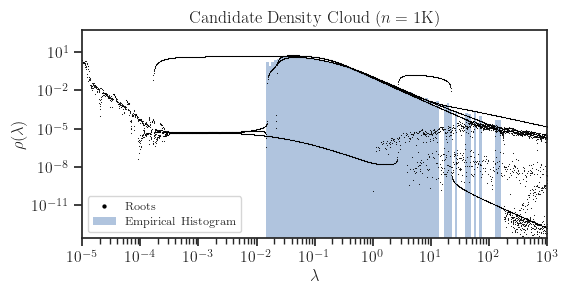

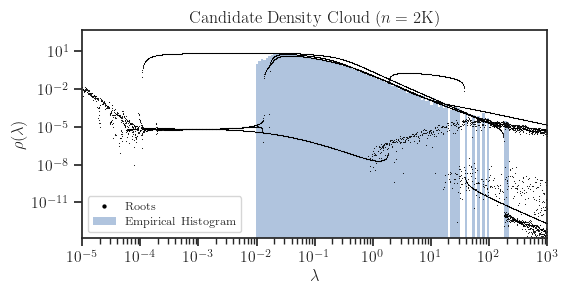

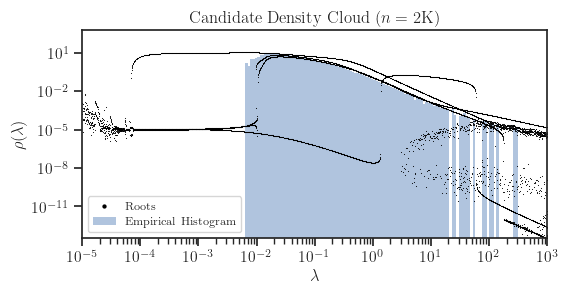

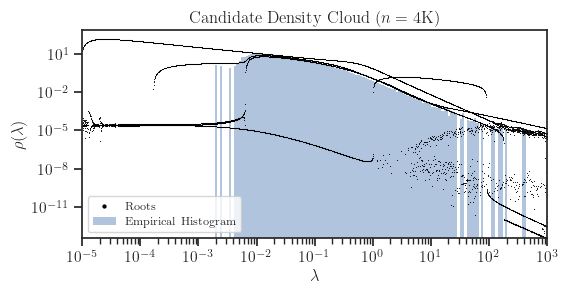

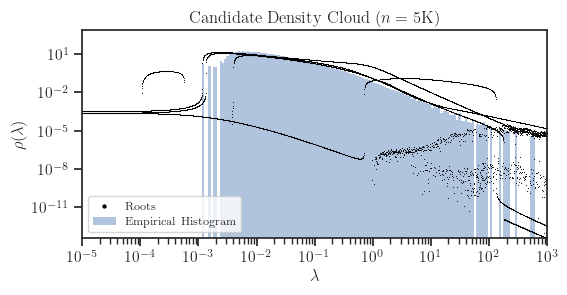

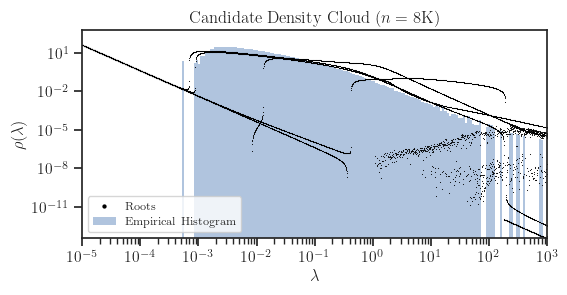

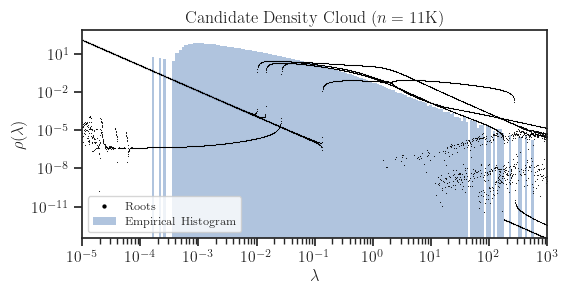

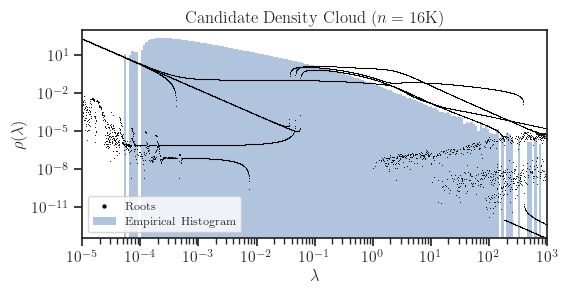

In [8]:
# Check if the density plotted above is formed by correct roots. For this,
# we plot all possible roots below.
x_min = 1e-5
x_max = 1e3
x_highres = numpy.geomspace(x_min, x_max, 2000)

# af.ratio = 0.25 # WORKED for 4K
# af.ratio = 0.229
# af.ratio = 0.229
af.ratio = 0.144
# af.ratio = 0.24

# for idx in range(start_idx, sizes.size):
# for idx in [start_idx, start_idx+1, sizes.size-1]:
# for idx in [start_idx, sizes.size-1]:
for idx in range(start_idx, sizes.size):
    af.candidates(
        size=sizes[idx],
        kind='deformed',
        # kind='free',
        x=x_highres,
        eig=eigs[idx],
        delta=None, markersize=0.6, latex=latex)

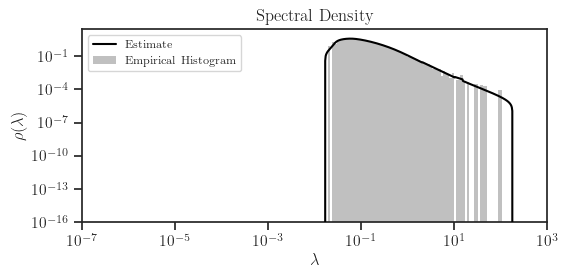


Mass: 0.99981981


In [9]:
# Plot density
x_min = 1e-7
x_max = 1e3
x0 = numpy.geomspace(x_min, x_max, 1000)
rho0 = af.density(x0, plot=True, latex=latex)

# Check mass (at start size)
print('')
mass = numpy.trapz(rho0, x0)
print(f'Mass: {mass:0.8f}')

Support (estimated from polynomial):
	Interval 1: (   0.0172,  177.5977)


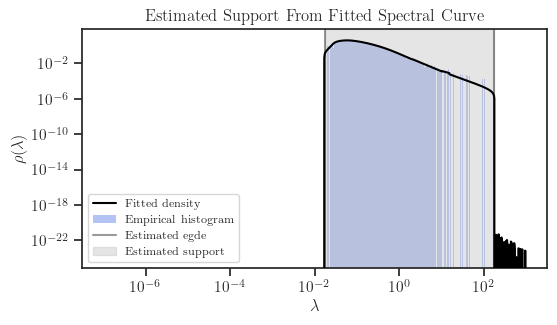

In [12]:
print('Support (estimated from polynomial):')

est_supp = af.support(refine=False, resplit_density=4, merge_threshold=0.1)

for i, supp in enumerate(est_supp):
    print(f'\tInterval {i+1}: ({supp[0]:>9.4f}, {supp[1]:>9.4f})')

with texplot.theme(use_latex=latex):
    alpha = 0.4
    fig, ax = plt.subplots(figsize=(6, 3.1))
    ax.plot(x0, rho0, color='black', zorder=10, label='Fitted density')
    
    bins = numpy.geomspace(
        numpy.min(eigs[start_idx]), numpy.max(eigs[start_idx]), 150)
    ax.hist(eigs[start_idx], bins, density=True,color='royalblue',
            alpha=0.4, zorder=1, edgecolor='none',
            label='Empirical histogram')
    
    for i in range(len(est_supp)):
        label = 'Estimated egde' if i == 0 else ''
        ax.axvline(est_supp[i][0], linestyle='-', color='black', alpha=alpha, label=label)
        ax.axvline(est_supp[i][1], linestyle='-', color='black', alpha=alpha)
    
        label = 'Estimated support' if i == 0 else ''
        ax.axvspan(est_supp[i][0], est_supp[i][1], color='silver', alpha=alpha, label=label)
    
    ax.set_xscale('log')
    ax.set_yscale('log')
    # ax.set_xlim([x[0], x[-1]])
    ax.set_xlabel(r'$\lambda$')
    ax.set_ylabel(r'$\rho(\lambda)$')
    ax.legend(fontsize='x-small', loc='lower left')
    ax.set_title('Estimated Support From Fitted Spectral Curve')
    plt.show()

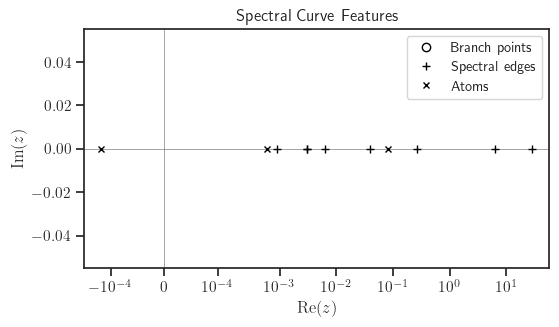


i   Branch Points        Spectral Edge
--  -------------------  -------------


In [10]:
# Branch points
bp = af.branch_points(tol=1e-16, real_tol=1e-16, plot=True, latex=latex)

# A branch point on real axis is a candidate to also be a spectral edge.
# Those with near zero imaginary part are flagged as maybe a spectral edge.
print('\ni   Branch Points        Spectral Edge')
print('--  -------------------  -------------')
for i in range(bp.size):
    print(f'{i+1}   {bp[i].real:>+8.4f}{bp[i].imag:>+5.3e}i', end='  ')
    if numpy.abs(bp[i].imag) < 1e-14:
        print('Maybe')
    else:
        print('No')

# Free Decompression

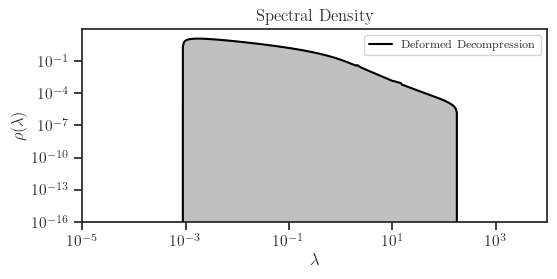

In [10]:
# Choosing the largest sub-matrix size to decompress to
# end_idx = sizes.size - 1
end_idx = 6

# Subset of sizes to apply free decompression
fd_sizes = sizes[start_idx:end_idx+1]

# x span of decompression
x_min = 1e-5
x_max = 1e4
x = numpy.geomspace(x_min, x_max, 500)

newton_opt = dict(
    dt_max=0.001,
    dt_min=1e-10,
    tol=1e-10,
    max_iter=1000,
    parallel=True,
    # parallel=False,
    n_jobs=24,
    log_mode=False,
    pair_enable=True,
    pair_gap_factor=10.0,
)

# Using method of characteristics (MoC) with 2x2 Newton and
# predictor/corrector (PC) to stabilize and speedup convergence
rho = af.decompress(
    fd_sizes, x=x,
    kind='deformed',
    # kind='free',
    method='moc', min_n_times=100,
    newton_opt=newton_opt, return_atoms=False, atom_eps=0.0,
    verbose=False, plot=True, latex=latex)

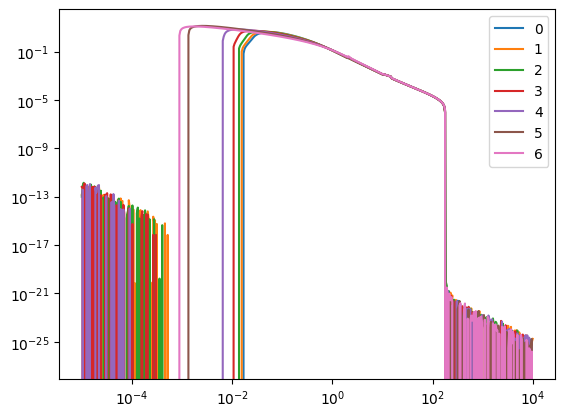

In [11]:
for i in range(rho.shape[0]):
    plt.plot(x, rho[i, :], label=f'{i}')
plt.xscale('log')
plt.yscale('log')
plt.legend()
plt.show()

In [12]:
rho_clean = numpy.copy(rho)
rho_dash = numpy.copy(rho)

rho_clean = numpy.abs(rho_clean)
rho_dash = numpy.abs(rho_dash)

# for i in range(rho_clean.shape[0]):

#     # Dnsity below Poisson kenrel delta floor is technically zero
#     poisson = (af.delta / numpy.pi) / (x**2 + af.delta**2)
#     small = rho_clean[i] < poisson
#     rho_clean[i, small] = 0.0
#     rho_dash[i, small] = 0.0

#     # Trim left edge that follows Tracy-Widom or extreme universaility
#     # We will plot left edge later below
#     left = x < numpy.quantile(eigs[start_idx+i], 1e-4)
#     # left = x < numpy.nanmin(eigs[start_idx+i])
#     left2 = x < numpy.quantile(eigs[start_idx+i], 1e-1)

#     if i == 0:
#         rho_clean[i, left] = 0
#     else:
#         rho_clean[i, left] = numpy.nan

#     # if i > 0:
#     rho_dash[i, left] = 1e-16
#     rho_dash[i, numpy.logical_not(left2)] = numpy.nan

Plot saved to "/home/sia/work/github/freealg/notebooks/./plots/stl-flow.pdf".


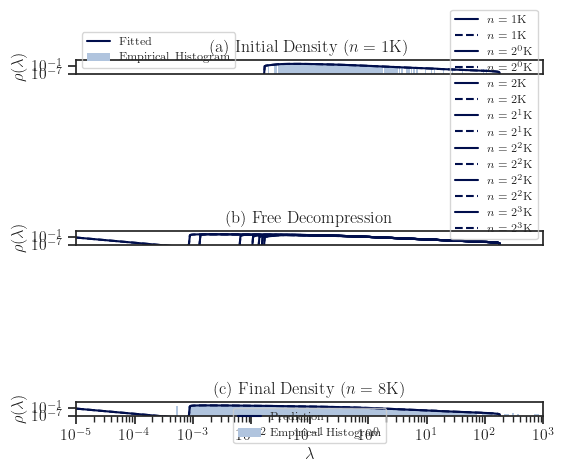

In [13]:
%matplotlib inline
plot_flow(fd_sizes, x, rho_clean, eigs[start_idx], eigs[end_idx], delta=af.delta,
          rho_dash=rho_dash,
          figsize=(5.8, 4.6),
          xlim=(1e-5, 1e3),
          ylim=(1e-7, 5e3),
          nbins=(350, 450),
          share_ax=True,
          layout='vertical',
          title='Free Decompression',
          plot_middle=True,
          plot_floor=False,
          cmap=plt.cm.ocean,
          c_range=(0.3, 0.3001),
          hist_color='lightsteelblue',
          label_mode='pow-int',
          log=True,
          latex=latex,
          save=join(plot_dir, save_filename + '-flow.pdf'))

Plot saved to "/home/sia/work/github/freealg/notebooks/./plots/stl-flow.pdf".


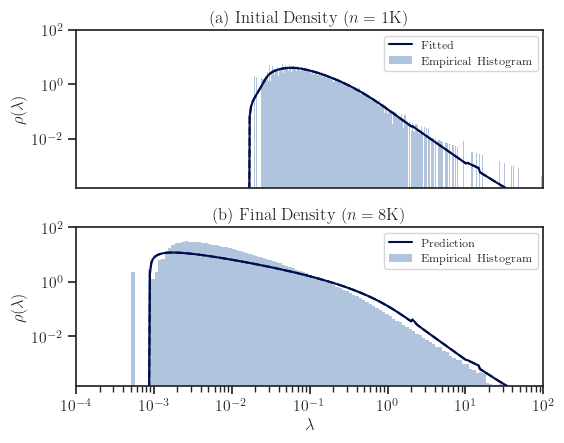

In [14]:
%matplotlib inline
plot_flow(fd_sizes, x, rho_clean, eigs[start_idx], eigs[end_idx], delta=af.delta,
          rho_dash=rho_dash,
          figsize=(5.8, 4.6),
          xlim=(1e-4, 1e2),
          ylim=(1.5e-4, 1e2),
          nbins=(350, 450),
          share_ax=True,
          layout='vertical',
          title='Free Decompression',
          plot_middle=False,
          plot_floor=False,
          cmap=plt.cm.ocean,
          c_range=(0.3, 0.3001),
          hist_color='lightsteelblue',
          label_mode='pow-int',
          log=True,
          latex=latex,
          save=join(plot_dir, save_filename + '-flow.pdf'))

Plot saved to "/home/sia/work/github/freealg/notebooks/./plots/stl-ridge.pdf".


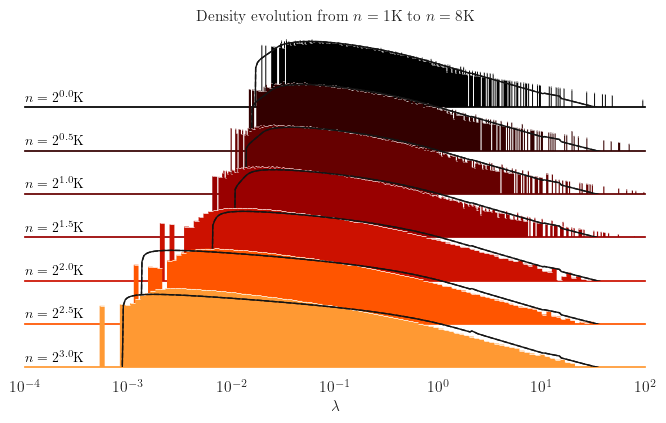

In [16]:
mask = x > numpy.min(eigs[end_idx])
gray = 0.08

%matplotlib inline
ridgeplot(sizes[start_idx:end_idx+1], x=x[mask], rho=rho_clean[:, mask],
          eigs=eigs[start_idx:end_idx+1], rho_dash=rho_dash[:, mask],
          log=True, ylim=(1.5e-4, 1e2), scaley=False, hspace=-0.5,
          cmap=plt.cm.gist_heat, c_range=(0, 0.8),
          rho_color=(gray, gray, gray),
          text_side='left', xlim=(1e-4, 1e2), figsize=(8, 4.5),
          # label_mode='pow-int',
          label_mode='pow-dec',
          latex=latex, nbins=395,
          title=r'Density evolution from $n=1$K to $n=8$K',
          save=join(plot_dir, save_filename + '-ridge.pdf'))

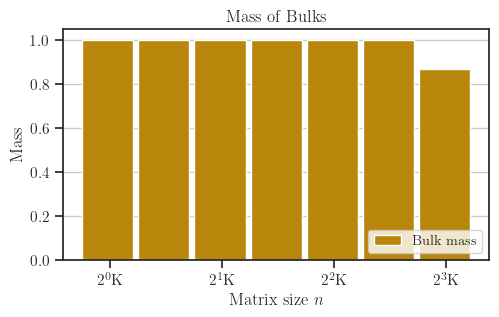

In [16]:
plot_mass(fd_sizes, x, rho, atoms=None, log_x=True, gap=0.9, latex=latex,
          save=False)

# Edge

In [17]:
end_idx = sizes.size - 1
fd_sizes = sizes[start_idx:end_idx+1]

t_final = numpy.log(fd_sizes[-1] / fd_sizes[0])
t = numpy.linspace(0, t_final, 500)

# cusps, info = af.cusp(t, kind='free', max_iter=1000, tol=1e-7, dedup_t_tol=1e-7,
#                       dedup_x_tol=1e-7, return_info=True)

# support = freealg.supp(eigs[start_idx], method='hist', tol=0, nbins=150, log=True)
est_supp = af.support(refine=False, resplit_density=4, mergewithout_threshold=0.01)

real_merged_edges, cusps = af.edge(
    t, kind='free', supp=est_supp, dt_max=0.01, max_iter=100, tol=1e-8)

print('Cusps:')
if len(cusps) > 0:
    for cusp in cusps:
        print(f'\tx: {cusp[0]:>0.3f}, t: {cusp[1]:>0.3f}')

Cusps:
	x: 178.865, t: 0.000
	x: 2837.251, t: 2.773


Plot saved to "/home/sia/work/github/freealg/notebooks/./plots/stl-edge.pdf".


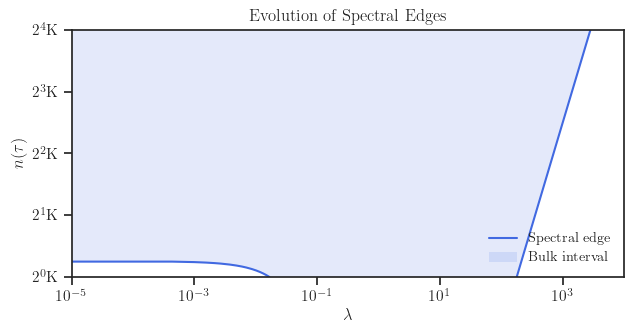

In [18]:
# Trim very close initial edges
# real_merged_edges_ = numpy.delete(real_merged_edges, [7, 8], axis=1)

plot_edges(t, real_merged_edges, cusps=None, sizes=fd_sizes,
           edge_color='royalblue', fill_color='royalblue', alpha=0.14,
           # edge_color='black', fill_color='gray', alpha=0.2,
           figsize=None, annotate=False, xlim=(1e-5, 1e4), log_x=True,
           log_y=True, flip_y=False,
           save=join(plot_dir, save_filename + '-edge.pdf'), latex=latex)

# Left Edge

In [19]:
# ==============
# fit shifted tw
# ==============

def fit_shifted_tw(sizes, min_eigs, sizes_eval, ngrid=2000):
    """
    Shifted Tracy-Widom lambda(n) = lambda(infty) + c n^{-2/3}.
    """
    
    sizes = numpy.asarray(sizes, float)
    min_eigs = numpy.asarray(min_eigs, float)
    sizes_eval = numpy.asarray(sizes_eval, float)

    z = sizes**(-2/3)
    agrid = numpy.linspace(0.0, float(numpy.min(min_eigs) * 0.999), ngrid)

    best_a_inf, best_C, best_mse = None, None, numpy.inf
    for a_inf in agrid:
        C = numpy.dot(z, min_eigs - a_inf) / numpy.dot(z, z)
        fit = a_inf + C * z
        mse = numpy.mean((min_eigs - fit)**2)
        if mse < best_mse:
            best_a_inf, best_C, best_mse = a_inf, C, mse

    left_edges_eval = best_a_inf + best_C * sizes_eval**(-2/3)
    
    return left_edges_eval, {"a_inf": best_a_inf, "C": best_C}

# ===========
# fit semilog
# ===========

def fit_semilog(sizes, min_eigs, sizes_eval):
    """
    Semilog lambda(n) = a + b*n.
    """
    
    sizes = numpy.asarray(sizes, float)
    min_eigs = numpy.asarray(min_eigs, float)
    sizes_eval = numpy.asarray(sizes_eval, float)

    m, b = numpy.polyfit(sizes, numpy.log(min_eigs), 1)
    left_edges_eval = numpy.exp(m * sizes_eval + b)
    
    return left_edges_eval, {"m": m, "b": b}

TW points: size, q, edge
[[1.00000000e+03 1.00000000e-07 1.92036696e-02]
 [1.41400000e+03 1.00000000e-07 1.45350637e-02]]
LL points: size, q, edge
[[2.00000000e+03 1.00000000e-03 1.07687732e-02]
 [2.82800000e+03 1.00000000e-03 7.11741991e-03]
 [4.00000000e+03 1.00000000e-03 4.24048443e-03]
 [5.65600000e+03 1.00000000e-03 2.38340517e-03]
 [8.00000000e+03 1.00000000e-03 1.01821792e-03]]
Plot saved to "/home/sia/work/github/freealg/notebooks/./plots/stl-left-edge.pdf".


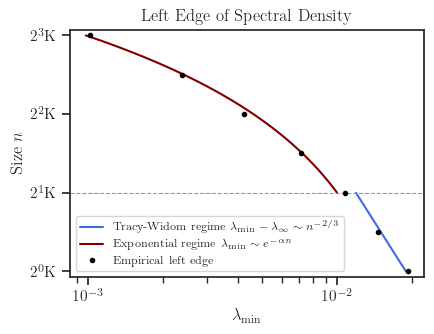

In [21]:
regime_idx = 1
plot_end_idx = numpy.where(sizes == 8000)[0][0]

sizes_plot = sizes[:plot_end_idx + 1]
eigs_plot = eigs[:plot_end_idx + 1]

q_tw = 1e-7
q_ll = 1e-3

# TW fit uses points 0..regime_idx
tw_idx = numpy.arange(0, regime_idx + 1)

# LL fit uses points regime_idx+1..end
ll_idx = numpy.arange(regime_idx + 1, len(sizes_plot))

min_eigs_tw = numpy.array([
    numpy.quantile(eigs_plot[i], q_tw) for i in tw_idx
])

min_eigs_ll = numpy.array([
    numpy.quantile(eigs_plot[i], q_ll) for i in ll_idx
])

# For plotting empirical points
min_eigs_plot = numpy.empty(len(sizes_plot))
min_eigs_plot[tw_idx] = min_eigs_tw
min_eigs_plot[ll_idx] = min_eigs_ll

print("TW points: size, q, edge")
print(numpy.c_[sizes_plot[tw_idx], numpy.full(tw_idx.size, q_tw), min_eigs_tw])
print("LL points: size, q, edge")
print(numpy.c_[sizes_plot[ll_idx], numpy.full(ll_idx.size, q_ll), min_eigs_ll])

# TW: fit on TW points, but plot until first LL point
tw_sizes = numpy.geomspace(sizes_plot[tw_idx[0]], sizes_plot[ll_idx[0]], 100)
tw_edge, tw_param = fit_shifted_tw(
    sizes_plot[tw_idx],
    min_eigs_tw,
    tw_sizes,
)

# LL: fit and plot from first LL point onward
ll_sizes = numpy.geomspace(sizes_plot[ll_idx[0]], sizes_plot[ll_idx[-1]], 100)
ll_edge, ll_param = fit_semilog(
    sizes_plot[ll_idx],
    min_eigs_ll,
    ll_sizes,
)

with texplot.theme(use_latex=latex):
    fig, ax = plt.subplots(figsize=(4.5, 3.5), ncols=1, sharey=False)

    ax.plot(
        tw_edge,
        tw_sizes,
        '-',
        color='royalblue',
        label=r'Tracy-Widom regime $\lambda_{\mathrm{min}} - \lambda_{\infty} \sim n^{-2/3}$',
    )
    ax.plot(
        ll_edge,
        ll_sizes,
        '-',
        color='maroon',
        label=r'Exponential regime $\lambda_{\mathrm{min}} \sim e^{-\alpha n}$',
    )

    ax.axhline(
        sizes_plot[ll_idx[0]],
        linestyle='--',
        color='0.6',
        linewidth=0.8,
    )

    ax.plot(
        min_eigs_plot,
        sizes_plot,
        'o',
        markersize=3,
        color='black',
        label='Empirical left edge',
    )

    ax.set_ylim([sizes_plot[0] / 1.05, sizes_plot[-1] * 1.05])
    ax.set_xscale('log')
    ax.set_yscale('log', base=2)

    ax.set_xlabel(r'$\lambda_{\mathrm{min}}$')
    ax.set_ylabel(r'Size $n$')
    ax.set_title('Left Edge of Spectral Density')

    ax.yaxis.set_major_locator(mticker.LogLocator(base=2, subs=(1000/512.0,)))
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(_k_pow2_formatter))

    ax.legend(fontsize='x-small', loc='lower left', facecolor='none')

    plt.tight_layout()

    import matplotlib.transforms as mtransforms
    fig.canvas.draw()
    bbox = fig.get_tightbbox(fig.canvas.get_renderer())
    pad = 0.75 / 72.0
    bbox = mtransforms.Bbox.from_extents(
        bbox.x0 - pad,
        bbox.y0 - pad,
        bbox.x1 + pad,
        bbox.y1 + pad,
    )

    full_save_filename = join(plot_dir, save_filename + '-left-edge.pdf')
    save_status = True
    texplot.show_or_save_plot(
        plt,
        default_filename=full_save_filename,
        transparent_background=True,
        dpi=200,
        bbox_inches=bbox,
        show_and_save=save_status,
        verbose=True,
    )

# Density and Left Edge

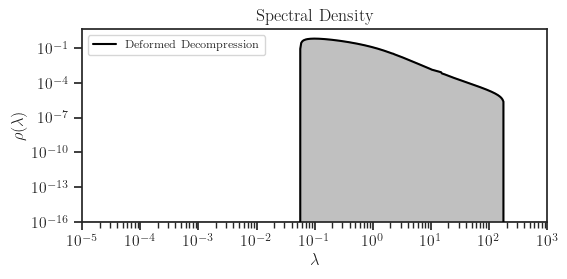

In [210]:
fd_sizes_plot = numpy.geomspace(sizes[start_idx], sizes[end_idx], t.size)

# x span of decompression
x_min = 1e-5
x_max = 1e3
x = numpy.geomspace(x_min, x_max, 500)

newton_opt = dict(
    dt_max=0.001,
    dt_min=1e-10,
    tol=1e-10,
    max_iter=1000,
    parallel=True,
    # parallel=False,
    n_jobs=24,
    log_mode=False,
    pair_enable=True,
    pair_gap_factor=10.0,
)

# Using method of characteristics (MoC) with 2x2 Newton and
# predictor/corrector (PC) to stabilize and speedup convergence
rho_plot = af.decompress(
    fd_sizes_plot, x=x, kind='deformed', method='moc', min_n_times=100,
    newton_opt=newton_opt, return_atoms=False, atom_eps=0.0,
    verbose=False, plot=True, latex=latex)

In [211]:
tw_idx = fd_sizes_plot <= sizes[regime_idx]
ll_idx = fd_sizes_plot > sizes[regime_idx]

tw_n = fd_sizes_plot[tw_idx]
ll_n = fd_sizes_plot[ll_idx]

left_edges = numpy.zeros_like(fd_sizes_plot)

# Shifted Tracy-Widom regime
left_edges[tw_idx] = tw_param['a_inf'] + tw_param['C'] * fd_sizes_plot[tw_idx]**(-2/3)

# Log-linear (exponential) regime
left_edges[ll_idx] = numpy.exp(ll_param['m'] * fd_sizes_plot[ll_idx] + ll_param['b'])

In [214]:
# Trim very close initial edges or spurious edges
# real_merged_edges_ = numpy.delete(real_merged_edges, [5, 6], axis=1)
real_merged_edges_ = numpy.copy(real_merged_edges)

Plot saved to "/home/eecs/sameli/freealg/notebooks/./plots/stl-edge2.pdf".


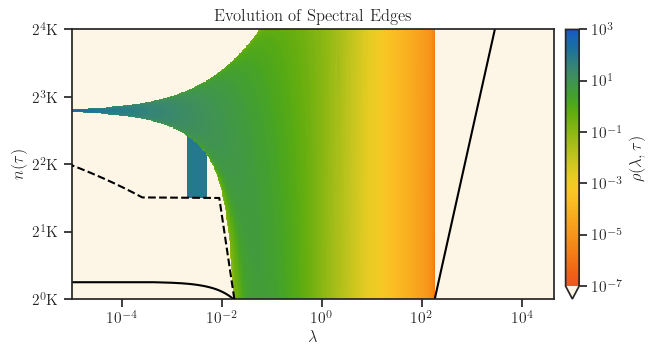

In [215]:
import colorcet as cc
from matplotlib.colors import LogNorm

t_ = sizes[start_idx] * numpy.exp(t)
xx, tt_ = numpy.meshgrid(x, t_)

poisson = (af.delta / numpy.pi) / (xx**2 + af.delta**2)
r = numpy.copy(rho_plot)
# r = numpy.abs(r)
# r[r < poisson] = numpy.nan
# r[r < poisson] = poisson[r < poisson]

# r[(r < 1e-7) & numpy.logical_not(near_cusp)] = numpy.nan
# r[(numpy.abs(r) < 1e-7)] = numpy.nan
r[r < 1e-7] = numpy.nan

# Repair nan points very close to cusp
near_cusp = (tt_ < 8e3) & (xx > 2e-3) & (xx < 5e-3)
repair = near_cusp & numpy.isnan(r)
r[repair] = 1e2 # poisson[repair]
r[(xx < left_edges[:, None])] = numpy.nan


# t_emp = numpy.log(sizes[start_idx:end_idx+1] / sizes[start_idx])
# t_emp = sizes[start_idx:end_idx+1]
# e_emp = min_eigs[start_idx:end_idx+1]

# cmap = plt.cm.YlOrRd
cmap = cc.cm.CET_R1_r
# cmap = cc.cm.CET_R4_r
cmap_trim = cmap.from_list('trimmed', cmap(numpy.linspace(0.2, 0.95, 256)))
bg_color = 'oldlace'
cmap_trim.set_under(bg_color)
# cmap_trim = cmap.from_list('trimmed', cmap(numpy.linspace(0.1, 0.7, 256)))

with texplot.theme(use_latex=True):
    fig, ax = plt.subplots(figsize=(7.5, 3.5))

    p = ax.pcolormesh(xx, tt_, r,
                      # norm=LogNorm(vmin=numpy.nanmin(r), vmax=numpy.nanmax(r)),
                      norm=LogNorm(vmin=1e-7, vmax=1e3),
                      cmap=cmap_trim, rasterized=True)
    
    ax.plot(real_merged_edges_, t_, color='0.0')
    # ax.plot(e_emp, t_emp, '--', color='black', zorder=10)
    ax.plot(left_edges, t_, '--', color='black', zorder=10)
    
    ax.set_facecolor(bg_color)
    
    ax.set_ylim([t_[0], t_[-1]])
    ax.set_xscale('log')

    # cbar = plt.colorbar(p, pad=0.02)
    cbar = plt.colorbar(p, pad=0.02, extend='min')
    cbar.set_label(r'$\rho(\lambda, \tau)$')
    cbar.solids.set_rasterized(True)
    cbar.ax.minorticks_off()

    cbar.ax.yaxis.set_major_locator(mticker.LogLocator(base=10))
    cbar.ax.yaxis.set_minor_locator(mticker.LogLocator(base=10, subs='auto'))
    cbar.ax.yaxis.set_minor_formatter(mticker.NullFormatter())

    ax.set_yscale('log', base=2)
    ax.yaxis.set_major_locator(mticker.LogLocator(base=2, subs=(1000/512.0,)))
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(_k_pow2_formatter))

    ax.set_xlabel(r'$\lambda$')
    ax.set_ylabel(r'$n(\tau)$')
    ax.set_title('Evolution of Spectral Edges')
    # plt.show()

    fig.patch.set_alpha(0)

    # Zero pad on left, right, and top of canvas
    import matplotlib.transforms as mtransforms
    fig.canvas.draw()
    bbox = fig.get_tightbbox(fig.canvas.get_renderer())
    pad = 0.5 / 72.0
    bbox = mtransforms.Bbox.from_extents(bbox.x0-pad, bbox.y0-pad,
                                         bbox.x1+pad, bbox.y1+pad)

    full_save_filename = join(plot_dir, save_filename + '-edge2.pdf')
    save_status = True
    save_status = True
    texplot.show_or_save_plot(plt, default_filename=full_save_filename,
                                  transparent_background=False, dpi=200,
                                  bbox_inches=bbox,
                                  show_and_save=save_status, verbose=True)

# Tables

In [216]:
# ================
# set delta_ladder
# ================

def set_delta_ladder(delta_ladder_size, method, fit_degree=2):
    """
    To benchmakr with only ont evaluation of density at one
    delta distance, set af.delta_ladder, like

    >>> set_delta_ladder(delta_ladder_size=1, method='direct', fit_degree=2)

    To return back to previosu behavior, set

    >>> set_delta_ladder(delta_ladder_size=4, method='chebfit', fit_degree=2)
    """
    
    af.inv_stieltjes_opt['delta_ladder_size'] = delta_ladder_size
    af.inv_stieltjes_opt['method'] = method
    af.inv_stieltjes_opt['fit_degree'] = fit_degree
        
    delta_ladder_grid = inv_stieltjes_opt['delta_ladder_grid']
    delta_ladder_ratio = inv_stieltjes_opt['delta_ladder_ratio']
    delta_ladder_size = inv_stieltjes_opt['delta_ladder_size']
    
    # Type of grid to produces multiple deltas for Plemelj
    if delta_ladder_grid == 'geometric':
        af.delta_ladder = af.delta * (
                delta_ladder_ratio **
                numpy.arange(delta_ladder_size, dtype=int))
    elif delta_ladder_grid == 'linear':
        af.delta_ladder = af.delta * \
            numpy.arange(1, delta_ladder_size+1, dtype=int)

    print('\nChanged af.delta_ladder to:')
    print(af.delta_ladder)
    print('')

# Runtime

To correctly measure runtime, do these:

1. `ssh mm340`
2. Export these
   ```
       export OMP_NUM_THREADS=1
       export OPENBLAS_NUM_THREADS=1
       export MKL_NUM_THREADS=1
       export NUMEXPR_NUM_THREADS=1
   ```
3. In `newton_opt`, set
   ```
       parallel=False
       n_jobs=1
   ```

In [217]:
import time, resource

def cpu_total_with_children():
    self = resource.getrusage(resource.RUSAGE_SELF)
    kids = resource.getrusage(resource.RUSAGE_CHILDREN)
    return self.ru_utime + self.ru_stime + kids.ru_utime + kids.ru_stime

# Copy settigns so we can revert it later
orig_delta_ladder_size = af.inv_stieltjes_opt['delta_ladder_size']
orig_method = af.inv_stieltjes_opt['method']
orig_fit_degree = af.inv_stieltjes_opt['fit_degree']

set_delta_ladder(delta_ladder_size=1, method='direct')

# Choosing the largest sub-matrix size to decompress to
end_idx = sizes.size - 1
fd_sizes = sizes[start_idx:end_idx+1]

# x span of decompression
x_min = 1e-5
x_max = 1e3
x = numpy.geomspace(x_min, x_max, 200)

newton_opt = dict(
    dt_max=0.001,
    dt_min=1e-10,
    tol=1e-8,
    max_iter=1000,
    parallel=False,
    n_jobs=1,
    log_mode=True,
    pair_enable=True,
    pair_gap_factor=10.0,
)

repeats = 5
fd_wall_times = numpy.zeros((fd_sizes.size,), dtype=float)
fd_proc_times = numpy.zeros((fd_sizes.size,), dtype=float)

i=0
print(f'Size: {fd_sizes[i]:>5d} ' + '.'*repeats, end='')
print(f' | fd wall time: {fd_wall_times[i]:>6.1f}'
      f' | fd proc time: {fd_proc_times[i]:>6.1f}'
      f' | direct proc time: {proc_times[i]:>9.1f}')

for i in numpy.arange(1, fd_sizes.size):

    print(f'Size: {fd_sizes[i]:>5d} ', end='')

    for j in range(repeats):

        print(f'.', end='')

        init_wall_time = time.time()
        init_proc_time = cpu_total_with_children()
        # init_proc_time = time.process_time()

        min_n_times = int(100 * fd_sizes[i] / fd_sizes[-1])
        
        rho_bnch, _ = af.decompress(
            fd_sizes[0:i+1], x=x, kind='free', method='moc', min_n_times=min_n_times,
            newton_opt=newton_opt, return_atoms=True, atom_eps=0.0,
            verbose=False, plot=False, latex=latex)

        fd_wall_times[i] += time.time() - init_wall_time
        fd_proc_times[i] += cpu_total_with_children() - init_proc_time
        # fd_proc_times[i] += time.process_time() - init_proc_time

    fd_wall_times[i] /= repeats
    fd_proc_times[i] /= repeats

    print(f' | fd wall time: {fd_wall_times[i]:>6.1f}'
          f' | fd proc time: {fd_proc_times[i]:>6.1f}'
          f' | direct proc time: {proc_times[start_idx+i]:>9.1f}')

# Revert back to the original setting 
af.inv_stieltjes_opt['delta_ladder_size'] = orig_delta_ladder_size
af.inv_stieltjes_opt['method'] = orig_method
af.inv_stieltjes_opt['fit_degree'] = orig_fit_degree
set_delta_ladder(orig_delta_ladder_size, orig_method)


Changed af.delta_ladder to:
[1.e-07]

Size:  1000 ..... | fd wall time:    0.0 | fd proc time:    0.0 | direct proc time:       4.2
Size:  1414 ..... | fd wall time:    1.4 | fd proc time:    3.0 | direct proc time:       8.7
Size:  2000 ..... | fd wall time:    0.4 | fd proc time:    2.1 | direct proc time:      14.0
Size:  2828 ..... | fd wall time:    0.6 | fd proc time:    2.4 | direct proc time:      36.5
Size:  4000 ..... | fd wall time:    0.9 | fd proc time:    2.7 | direct proc time:      69.5
Size:  5656 ..... | fd wall time:    1.5 | fd proc time:    3.2 | direct proc time:     274.2
Size:  8000 ..... | fd wall time:    2.0 | fd proc time:    3.7 | direct proc time:     579.6
Size: 11313 ..... | fd wall time:    2.9 | fd proc time:    4.6 | direct proc time:    1691.7
Size: 16000 ..... | fd wall time:    4.0 | fd proc time:    5.7 | direct proc time:    5002.6

Changed af.delta_ladder to:
[1.e-07 2.e-07 3.e-07 4.e-07]



# Distributional Comparison (Table)

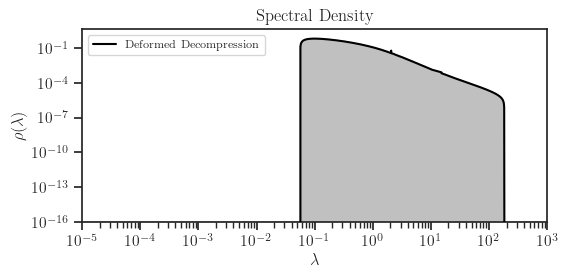

In [219]:
# Choosing the largest sub-matrix size to decompress to
end_idx = sizes.size - 1

# Subset of sizes to apply free decompression
fd_sizes = sizes[start_idx:end_idx+1]

# x span of decompression
x_min = 1e-5
x_max = 1e3
x = numpy.geomspace(x_min, x_max, 2000)

newton_opt = dict(
    dt_max=0.001,
    dt_min=1e-10,
    tol=1e-10,
    max_iter=1000,
    parallel=True,
    # parallel=False,
    n_jobs=24,
    log_mode=False,
    pair_enable=True,
    pair_gap_factor=10.0,
)

# Using method of characteristics (MoC) with 2x2 Newton and
# predictor/corrector (PC) to stabilize and speedup convergence
rho = af.decompress(
    fd_sizes, x=x, kind='deformed', method='moc', min_n_times=100,
    newton_opt=newton_opt, return_atoms=False, atom_eps=0.0,
    verbose=False, plot=True, latex=latex)

In [221]:
rho_cut = rho.copy()
# for i in range(rho_cut.shape[0]):
#     rho_cut[i, x < numpy.min(eigs[start_idx + i])] = 0.0

In [222]:
import numpy
from scipy.stats import ks_2samp, wasserstein_distance
from freealg import sample


def sample_tv_log(eig_emp, eig_fd, bins=150, xrange=None):
    """Histogram-based TV using log-spaced bins."""
    if xrange is None:
        lo = max(min(eig_emp.min(), eig_fd.min()), numpy.finfo(float).tiny)
        hi = max(eig_emp.max(), eig_fd.max())
    else:
        lo, hi = xrange

    eig_emp = eig_emp[(eig_emp >= lo) & (eig_emp <= hi)]
    eig_fd = eig_fd[(eig_fd >= lo) & (eig_fd <= hi)]

    edges = numpy.geomspace(lo, hi, bins + 1)

    hist_emp, edges = numpy.histogram(eig_emp, bins=edges, density=True)
    hist_fd, _ = numpy.histogram(eig_fd, bins=edges, density=True)

    dx = numpy.diff(edges)
    return 0.5 * numpy.sum(numpy.abs(hist_emp - hist_fd) * dx)


def density_moment(rho_i, x, k):
    """Compute unnormalized int x^k rho(x) dx."""
    return numpy.trapz((x**k) * rho_i, x)


def gaussian_mmd2_biased(a, b, sigma=None, max_pts=4000, seed=0):
    """Biased Gaussian MMD^2. Returns value in [0, 2]."""
    rng = numpy.random.default_rng(seed)

    a = numpy.asarray(a)
    b = numpy.asarray(b)

    if a.size > max_pts:
        a = rng.choice(a, size=max_pts, replace=False)
    if b.size > max_pts:
        b = rng.choice(b, size=max_pts, replace=False)

    a = a[:, None]
    b = b[:, None]

    if sigma is None:
        z = numpy.vstack([a, b]).ravel()
        dz = numpy.abs(z[:, None] - z[None, :])
        sigma = numpy.median(dz[dz > 0])
        if not numpy.isfinite(sigma) or sigma <= 0:
            sigma = 1.0

    k_aa = numpy.exp(-0.5 * ((a - a.T) / sigma)**2).mean()
    k_bb = numpy.exp(-0.5 * ((b - b.T) / sigma)**2).mean()
    k_ab = numpy.exp(-0.5 * ((a - b.T) / sigma)**2).mean()

    return k_aa + k_bb - 2.0 * k_ab


tv = []
ks = []
w1 = []
w1_norm = []
mmd = []
mu1_err = []
mu2_err = []
std_err = []

for j, n in enumerate(fd_sizes):
    eig_emp = numpy.asarray(eigs[start_idx + j])
    rho_fd = rho_cut[j]

    eig_fd = sample(
        x, rho_fd,
        num_pts=eig_emp.size,
        method='qmc',
        seed=start_idx + j,
    )

    tv_i = sample_tv_log(
        eig_emp, eig_fd,
        bins=450,
        xrange=(numpy.min(eig_emp), numpy.max(eig_emp)),
    )

    ks_i = ks_2samp(eig_emp, eig_fd).statistic

    log_emp = numpy.log(eig_emp[eig_emp > 0])
    log_fd = numpy.log(eig_fd[eig_fd > 0])

    w1_i = wasserstein_distance(eig_emp, eig_fd)
    log_L_i = numpy.ptp(log_emp)
    w1_norm_i = wasserstein_distance(log_emp, log_fd) / log_L_i

    # MMD on log eigenvalues; report MMD^2 / 2 as a [0, 1]-scaled number.
    mmd_i = 0.5 * gaussian_mmd2_biased(
        log_emp, log_fd, sigma=None, max_pts=4000, seed=start_idx + j)

    mu1_emp = numpy.mean(eig_emp)
    mu2_emp = numpy.mean(eig_emp**2)
    std_emp = numpy.std(eig_emp)

    mu1_fd = density_moment(rho_fd, x, 1)
    mu2_fd = density_moment(rho_fd, x, 2)
    std_fd = numpy.sqrt(mu2_fd - mu1_fd**2)

    mu1_err_i = numpy.abs(mu1_fd - mu1_emp) / numpy.abs(mu1_emp)
    mu2_err_i = numpy.abs(mu2_fd - mu2_emp) / numpy.abs(mu2_emp)
    std_err_i = numpy.abs(std_fd - std_emp) / numpy.abs(std_emp)

    tv.append(tv_i)
    ks.append(ks_i)
    w1.append(w1_i)
    w1_norm.append(w1_norm_i)
    mmd.append(mmd_i)
    mu1_err.append(mu1_err_i)
    mu2_err.append(mu2_err_i)
    std_err.append(std_err_i)

tv = numpy.asarray(tv)
ks = numpy.asarray(ks)
w1 = numpy.asarray(w1)
w1_norm = numpy.asarray(w1_norm)
mmd = numpy.asarray(mmd)
mu1_err = numpy.asarray(mu1_err)
mu2_err = numpy.asarray(mu2_err)
std_err = numpy.asarray(std_err)

print(
    f"{'n':>6}  {'TV':>6}  {'KS':>6}  {'W1/L':>7}  {'MMD':>7}  "
    f"{'mu1 err':>8}  {'mu2 err':>8}  {'std err':>8}"
)
print("-" * 70)

for j, n in enumerate(fd_sizes):
    print(
        f"{int(n):6d}  "
        f"{100*tv[j]:5.1f}%  "
        f"{100*ks[j]:5.1f}%  "
        f"{100*w1_norm[j]:6.2f}%  "
        f"{100*mmd[j]:6.2f}%  "
        f"{100*mu1_err[j]:7.2f}%  "
        f"{100*mu2_err[j]:7.2f}%  "
        f"{100*std_err[j]:7.2f}%"
    )

     n      TV      KS     W1/L      MMD   mu1 err   mu2 err   std err
----------------------------------------------------------------------
  1000   10.7%    0.5%    0.23%    0.00%     0.51%     1.35%     0.68%
  1414   10.7%    5.3%    1.56%    0.17%     0.48%    31.03%    17.37%
  2000   11.7%    9.6%    2.84%    0.58%     0.25%    50.49%    30.22%
  2828   13.9%   12.7%    3.84%    1.05%     0.25%    64.94%    41.42%
  4000   15.3%   15.0%    1.24%    1.42%     0.05%    74.62%    50.24%
  5656   18.6%   16.3%    1.41%    1.73%     0.15%    81.73%    57.82%
  8000   25.1%   24.6%    2.34%    3.70%     0.03%    86.90%    64.31%
 11313   46.5%   46.2%    4.98%   13.50%     0.25%    90.61%    69.79%
 16000   66.5%   66.3%    7.36%   25.36%     0.53%    93.19%    74.28%
